In [1]:
import os
from pathlib import Path
os.chdir(Path.cwd().parent)

In [2]:
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command
from langgraph.checkpoint.memory import InMemorySaver

from src.risklens2.graph.state import CreditState
from src.risklens2.graph.nodes import company_research, industry_research, media_research, get_financials_input,financial_analysis, policy_assessment, credit_memo


In [3]:
graph = StateGraph(state_schema=CreditState)

graph.add_node("company_research", company_research)
graph.add_node("industry_research", industry_research)
graph.add_node("media_research", media_research)
graph.add_node("get_financials_input", get_financials_input)
graph.add_node("financial_analysis", financial_analysis)
graph.add_node("policy_assessment", policy_assessment)
graph.add_node("credit_memo", credit_memo)

graph.add_edge(START, "company_research")
graph.add_edge("company_research", "industry_research")
graph.add_edge("company_research", "media_research")
graph.add_edge("industry_research", "get_financials_input")
graph.add_edge("media_research", "get_financials_input")

graph.add_edge("get_financials_input", "financial_analysis")
graph.add_edge("financial_analysis", "policy_assessment")
graph.add_edge("policy_assessment", "credit_memo")
graph.add_edge("credit_memo", END)

workflow = graph.compile(checkpointer=InMemorySaver())


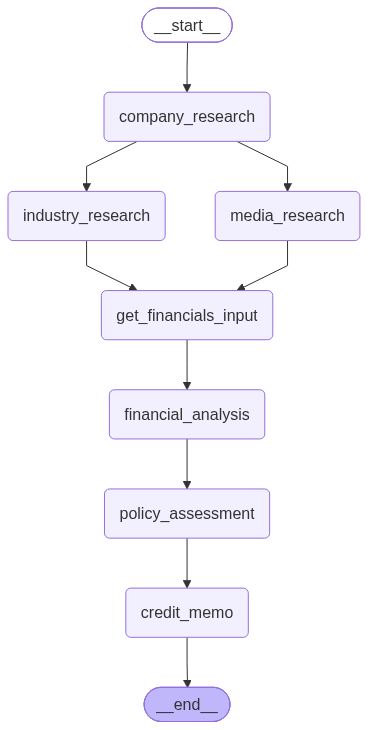

In [4]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [5]:
initial_state = {
    "company_number": "SC196478"
}

config = {"configurable": {"thread_id": 1}}

In [ ]:
interim_state = workflow.invoke(initial_state, config)

M B C C (FOODS) LIMITED ----- Adverse media checks running
industry_outlook being queried and evaluated
M B C C (FOODS) LIMITED ----- Adverse media checks running
M B C C (FOODS) LIMITED ----- Adverse media checks running
M B C C (FOODS) LIMITED ----- Adverse media checks running
TULI, Raju --- Adverse Media checks running
TULI, Sundeep --- Adverse Media checks running
TULI, Savitri --- Adverse Media checks running


In [ ]:
workflow.get_state(config = config)

Deserializing unregistered type risklens2.models.company_research_schemas.CompanyResearch from checkpoint. This will be blocked in a future version. Set LANGGRAPH_STRICT_MSGPACK=true to block now, or add to allowed_msgpack_modules to allow explicitly: [('risklens2.models.company_research_schemas', 'CompanyResearch')]
Deserializing unregistered type src.risklens2.models.industry_intelligence_schemas.IndustryIntelligence from checkpoint. This will be blocked in a future version. Set LANGGRAPH_STRICT_MSGPACK=true to block now, or add to allowed_msgpack_modules to allow explicitly: [('src.risklens2.models.industry_intelligence_schemas', 'IndustryIntelligence')]
Deserializing unregistered type src.risklens2.models.media_search_schemas.AdverseMediaInfo from checkpoint. This will be blocked in a future version. Set LANGGRAPH_STRICT_MSGPACK=true to block now, or add to allowed_msgpack_modules to allow explicitly: [('src.risklens2.models.media_search_schemas', 'AdverseMediaInfo')]


StateSnapshot(values={'company_number': 'SC196478', 'company_name': 'M B C C (FOODS) LIMITED', 'company_research': CompanyResearch(company_profile=CompanyProfile(company_name='M B C C (FOODS) LIMITED', company_number='SC196478', status='active', incorporation_date=datetime.datetime(1999, 5, 24, 0, 0), age=27, type='ltd', sic_code=['47290'], industry_names=['Other retail sale of food in specialised stores'], reg_address={'address_line_1': '7 Coates Crescent', 'locality': 'Edinburgh', 'postal_code': 'EH3 7AL'}, next_confirmation_statement_due=datetime.datetime(2027, 5, 22, 0, 0)), director_details=DirectorInfo(directors=[{'name': 'TULI, Raju', 'appointment_date': datetime.date(1999, 5, 24), 'nationality': 'British', 'tenure_in_years': 27.44}, {'name': 'TULI, Sundeep', 'appointment_date': datetime.date(1999, 5, 24), 'nationality': 'British', 'tenure_in_years': 27.44}, {'name': 'TULI, Savitri', 'appointment_date': datetime.date(2001, 9, 10), 'nationality': 'Indian', 'tenure_in_years': 25.1

In [ ]:
final_state = workflow.invoke(
    Command(
        resume={
            "revenue_cy": 15000000,
            "revenue_py": 10000000,
            "ebitda": 1200000,
            "net_profit": 650000,
            "cash": 450000,
            "current_assets": 3200000,
            "inventory": 750000,
            "current_liabilities": 2200000,
            "total_assets": 7800000,
            "total_liabilities": 4800000,
            "equity": 3000000,
            "total_debt": 2500000,
            "interest_expense": 180000
        }
    ), config=config
)

In [ ]:
final_state

{'company_number': 'SC196478',
 'company_name': 'M B C C (FOODS) LIMITED',
 'company_research': CompanyResearch(company_profile=CompanyProfile(company_name='M B C C (FOODS) LIMITED', company_number='SC196478', status='active', incorporation_date=datetime.datetime(1999, 5, 24, 0, 0), age=27, type='ltd', sic_code=['47290'], industry_names=['Other retail sale of food in specialised stores'], reg_address={'address_line_1': '7 Coates Crescent', 'locality': 'Edinburgh', 'postal_code': 'EH3 7AL'}, next_confirmation_statement_due=datetime.datetime(2027, 5, 22, 0, 0)), director_details=DirectorInfo(directors=[{'name': 'TULI, Raju', 'appointment_date': datetime.date(1999, 5, 24), 'nationality': 'British', 'tenure_in_years': 27.44}, {'name': 'TULI, Sundeep', 'appointment_date': datetime.date(1999, 5, 24), 'nationality': 'British', 'tenure_in_years': 27.44}, {'name': 'TULI, Savitri', 'appointment_date': datetime.date(2001, 9, 10), 'nationality': 'Indian', 'tenure_in_years': 25.14}], secretary=[{'n